# Depth check: does a longer maximum sequence length still help?

Before scanning many designs (Part C of the plan), this notebook asks one question: **up to which maximum sequence length $L_{\max}$ does the required number of shots per circuit still fall, and where does the signal of long circuits collapse into noise?** The limit $L_{\max}\le23$ of `random_seq_design` has been lifted (checked by `scripts/21_check_sequence_design.py`).

**Terms.**
- **PTM:** Pauli transfer matrix; the PTM elements are gauge-fixed as in [`PTM_PRECISION.md`](identifiability_and_cramer_rao/PTM_PRECISION.md) §2.2 (unitary gauge only).
- **LAN width:** $\sigma^{\rm LAN}_f=\sqrt{\mathbf d_f^\top F^+\mathbf d_f}$, the width under local asymptotic normality.
- **vT width:** the van Trees width with prior width $\tau=2\tau_0$ per tangent direction (PTM_PRECISION 3.7).
- **Rate resolution:** $\sigma(\mu)/\mu$ for the small Choi eigenvalues $\mu$ (incoherent rates); resolved if $\le0.5$, i.e. $u=\mu/\sigma(\mu)\ge2$ ([`VALIDITY.md`](identifiability_and_cramer_rao/VALIDITY.md) 4.4).
- **TVD:** total variation distance between two outcome distributions, $\tfrac12\sum_i|p_i-q_i|$.
- **GL gauge:** the full gauge group of invertible, trace-preserving frame changes $M$ ($R_g\to MR_gM^{-1}$ and the matching change of the state preparation and measurement, SPAM). The Kraus model has only its unitary part as an exact symmetry.

**Required shots per circuit** $m$ for a 95% half-width $\delta$ of the worst PTM element (each element separately, $z=1.96$), with the regime rule of the plan:
- **regime A** (bias cap $3\max_g(1-\mu_{1,g})<\delta/2$): $m_{\rm design}=m_{\rm vT}$, and LAN is the conservative end;
- **regime B** (otherwise): $m_{\rm design}=\max(m_{\rm LAN},m_{\rm rate})$, with $m_{\rm rate}$ the shots for $\max\sigma(\mu)/\mu\le0.5$.

**Evaluation points**, one $N$ and one design seed each (computed by [`scripts/23_depth_check.py`](identifiability_and_cramer_rao/scripts/23_depth_check.py), about 20 min):

| point | what | $N$ | expected regime |
|---|---|---|---|
| noise 0.05 prior | target + random noise, strength 0.05, seed 7 (hardware-like) | 600 | A |
| noise 0.3 truth | target + random noise, strength 0.3, seed 42 (old notebook's truth) | 1000 | B |
| IQMFakeApollo | the fake backend's noise model on qubits (0, 1), compressed to Kraus rank 4 | 1000 | B |

The fake-backend gate set is checked against Aer sampling of the fake backend by `scripts/22_check_fake_backend_gate_set.py`. It adds two things the Aer model lacks:
- thermal relaxation of idle qubits (during the Idle gate and the one-qubit gates);
- a 1% thermal excited population of the prepared state.

Without them, the Idle gate and the state would be exactly pure, which are singular points of the model.

In [1]:
import sys
sys.path.append("identifiability_and_cramer_rao/scripts")
from pathlib import Path
import numpy as np
import pandas as pd
import jax.numpy as jnp
import matplotlib.pyplot as plt

import ptm_design as pdz
from mGST.utility_functions_comparisons import get_target_operators_gate_set_name
from iqm.qiskit_iqm.fake_backends import IQMFakeApollo

pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
CACHE = Path("identifiability_and_cramer_rao/data/depth_check_2q.npz")
if not CACHE.exists():
    raise FileNotFoundError("run identifiability_and_cramer_rao/scripts/23_depth_check.py first (about 20 min)")
cache = np.load(CACHE, allow_pickle=True)
results, L_list, m_grid = cache["results"].item(), list(cache["L_list"]), cache["m_grid"]

delta, z, rate_threshold, m_cap = 1e-2, 1.96, 0.5, 1e4
# colour = quantity (fixed order), line style = with / without near-gauge directions
COLOR = {"LAN": "#2a78d6", "vT": "#eb6834", "rate": "#1baf7a", "design": "#0b0b0b"}
plt.rcParams.update({"axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
                     "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2})

/Users/emiliano.godinez/.pyenv/versions/3.11.10/envs/qcvv-env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Regimes of the evaluation points

- $1-\mu_1$ is the incoherent weight per gate.
- The bias cap $3(1-\mu_1)$ bounds, to first order, how much a PTM element can move if the estimate collapses the gate's incoherent part (PTM_PRECISION 3.5).
- For the fake backend the table below also shows the Choi weight discarded by the rank-4 model, and how much that truncation alone moves the PTM elements. That is a systematic floor which no design removes.

In [2]:
regime = {}
rows = []
for name, res in results.items():
    one_minus_mu1 = 1 - res["mu"][:, 0]
    cap = 3 * one_minus_mu1.max()
    regime[name] = "A" if cap < delta / 2 else "B"
    rows.append({"point": name, "N": res["N"], "max 1 - mu_1": one_minus_mu1.max(), "bias cap": cap, "regime": regime[name],
                 "tau0": res["tau0"], "smallest rate mu": res["mu_small"].min()})
display(pd.DataFrame(rows).round(5))

target, _ = get_target_operators_gate_set_name(gate_set_name="2QXYICZ")
fb4, fb_full, fb_table = pdz.fake_backend_gate_set(IQMFakeApollo(), [0, 1], target["kraus"], return_full=True)
fb_table.index = ["Idle", "Rx q0", "Rx q1", "Ry q0", "Ry q1", "CZ"]
fb_table["max |PTM change| from rank-4 truncation"] = np.abs(np.asarray(pdz.pauli_transfer_matrices(fb4[0])) - np.asarray(pdz.pauli_transfer_matrices(fb_full[0]))).max(axis=(1, 2))
print("IQMFakeApollo, qubits (0, 1):")
display(fb_table)

,point,N,max 1 - mu_1,bias cap,regime,tau0,smallest rate mu
0,noise 0.05 prior,600,0.00063,0.00188,A,0.00510,0.00007
1,noise 0.3 truth,1000,0.02492,0.07477,B,0.03265,0.00338
2,IQMFakeApollo,1000,0.01564,0.04691,B,0.01777,0.00032


INFO:2026-11-17 20:17:09,949:jax._src.xla_bridge:927: Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'


2026-11-17 20:17:09,949 - jax._src.xla_bridge - INFO - Unable to initialize backend 'rocm': module 'jaxlib.xla_extension' has no attribute 'GpuAllocatorConfig'


INFO:2026-11-17 20:17:09,950:jax._src.xla_bridge:927: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Pre

2026-11-17 20:17:09,950 - jax._src.xla_bridge - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: dlopen(libtpu.so, 0x0001): tried: 'libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OSlibtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/opt/homebrew/lib/libtpu.so' (no such file), '/System/Volumes/Preboot/Cryptexes/OS/opt/homebrew/lib/libtpu.so' (no such file), '/Users/emiliano.godinez/.pyenv/versions/3.11.10/lib/libtpu.so' (no such file), '/System/Volumes/Pr

IQMFakeApollo, qubits (0, 1):


,1 - mu_1,Choi weight beyond rank 4,mu_2..mu_6,max |PTM change| from rank-4 truncation
Idle,0.003657,0.000326,"[0.001591, 0.001417, 0.000323, 0.000323, 2e-06]",0.000649
Rx q0,0.005661,0.000721,"[0.002372, 0.001856, 0.000712, 0.000423, 0.000...",0.001431
Rx q1,0.005557,0.000685,"[0.00211, 0.002084, 0.000678, 0.000423, 0.000254]",0.001359
Ry q0,0.005661,0.000721,"[0.002372, 0.001856, 0.000712, 0.000423, 0.000...",0.001431
Ry q1,0.005557,0.000685,"[0.00211, 0.002084, 0.000678, 0.000423, 0.000254]",0.001359
CZ,0.025817,0.010341,"[0.007064, 0.006374, 0.002038, 0.002037, 0.000...",0.014591


## Required shots versus depth

Per point and $L_{\max}$, the required $m$ for $\delta=10^{-2}$:
- solid lines use all Fisher directions;
- dashed lines drop the directions that are, to within 1%, GL gauge directions (next section). They approximate GL-gauge-fixed quantities.

The dotted horizontal line is the shot cap $m=10^4$.

**What to look for:**
- the thick black curve ($m_{\rm design}$) should fall with $L_{\max}$;
- where it flattens, more depth stops paying;
- where it turns up, the long circuits have lost their signal.

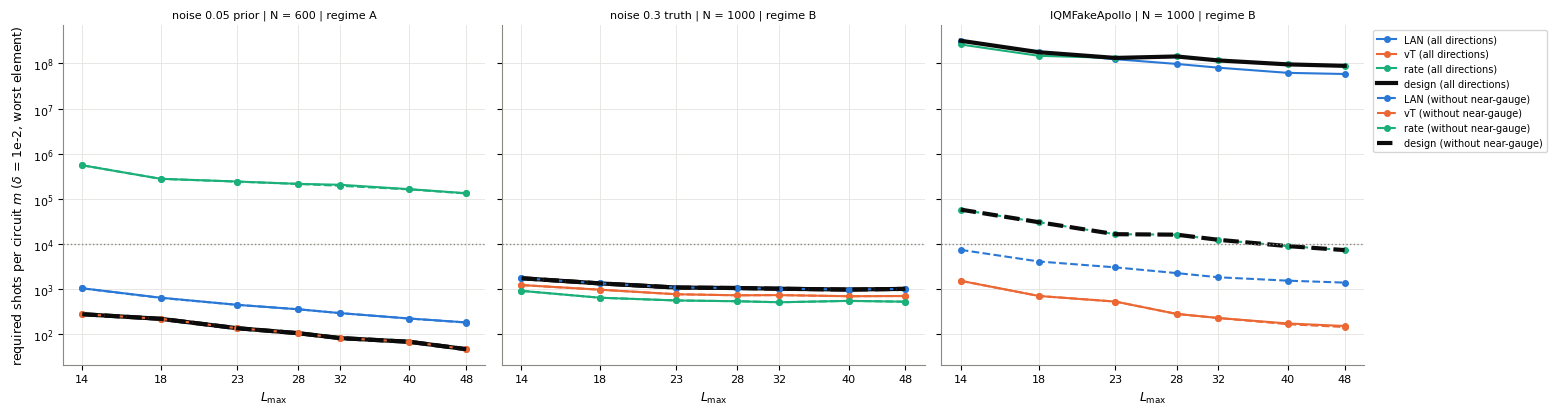

In [3]:
def m_needed(res, row, suffix=""):
    s1, vt, rate = row["sigma_lan1" + suffix], row["max_vt" + suffix], row["rate_sigma1" + suffix]
    out = {"LAN": (z * s1.max() / delta) ** 2,
           "vT": pdz.required_shots(z * vt, m_grid, delta),
           "rate": (np.max(rate / res["mu_small"]) / rate_threshold) ** 2,
           "LAN q95": (z * np.quantile(s1, 0.95) / delta) ** 2}
    return out


table = []
for name, res in results.items():
    for row in res["rows"]:
        for suffix, label in [("", "all directions"), ("_ng", "without near-gauge")]:
            m = m_needed(res, row, suffix)
            m["design"] = m["vT"] if regime[name] == "A" else max(m["LAN"], m["rate"])
            table.append({"point": name, "directions": label, "L_max": row["L"], **m, "near-gauge directions": row["n_near_gauge"]})
table = pd.DataFrame(table)

fig, axes = plt.subplots(1, len(results), figsize=(5.2 * len(results), 4.2), sharey=True)
for ax, name in zip(axes, results):
    for label, ls in [("all directions", "-"), ("without near-gauge", "--")]:
        t = table[(table.point == name) & (table.directions == label)]
        for q in ["LAN", "vT", "rate"]:
            ax.plot(t.L_max, t[q], ls, color=COLOR[q], lw=1.5, marker="o", ms=4, label=f"{q} ({label})")
        ax.plot(t.L_max, t["design"], ls, color=COLOR["design"], lw=3, label=f"design ({label})")
    ax.axhline(m_cap, color="#8a8984", ls=":", lw=1)
    ax.set(xscale="log", yscale="log", xlabel=r"$L_{\max}$", title=f"{name} | N = {results[name]['N']} | regime {regime[name]}")
    ax.set_xticks(L_list); ax.set_xticklabels(L_list); ax.minorticks_off()
axes[0].set_ylabel(r"required shots per circuit $m$ ($\delta$ = 1e-2, worst element)")
axes[-1].legend(fontsize=7, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

**Local exponents:** $d\log m_{\rm design}/d\log L_{\max}$ between neighbouring depths.
- $-1$ means doubling $L_{\max}$ halves the shots.
- $-0.3$ means it saves only about 20%.
- Above 0, more depth hurts.

In [4]:
def local_exponents(t, col="design"):
    L, m = t.L_max.to_numpy(float), t[col].to_numpy(float)
    return pd.Series(np.diff(np.log(m)) / np.diff(np.log(L)), index=[f"{int(a)}->{int(b)}" for a, b in zip(L[:-1], L[1:])])

exps = {(name, label): local_exponents(table[(table.point == name) & (table.directions == label)])
        for name in results for label in ["all directions", "without near-gauge"]}
display(pd.DataFrame(exps).T.round(2))
display(table.pivot_table(index=["point", "directions"], columns="L_max", values="design").round(0))

14->18  18->23  23->28  28->32  32->40  40->48
noise 0.05 prior all directions       -0.94   -1.95   -1.30   -1.86   -0.85   -2.07
                 without near-gauge   -0.94   -1.95   -1.30   -1.86   -0.85   -2.07
noise 0.3 truth  all directions       -1.05   -0.86   -0.13   -0.27   -0.19    0.19
                 without near-gauge   -1.05   -0.86   -0.13   -0.27   -0.19    0.19
IQMFakeApollo    all directions       -2.33   -1.19    0.38   -1.52   -0.90   -0.41
                 without near-gauge   -2.56   -2.49   -0.12   -1.96   -1.45   -1.11

L_max                                         14           18           23           28           32          40          48
point            directions                                                                                                 
IQMFakeApollo    all directions      318567058.0  177485299.0  132708123.0  143063361.0  116819720.0  95496502.0  88659233.0
                 without near-gauge      58092.0      30530.0      16592.0      16198.0      12472.0      9034.0      7378.0
noise 0.05 prior all directions            281.0        222.0        138.0        107.0         83.0        69.0        47.0
                 without near-gauge        281.0        222.0        138.0        107.0         83.0        69.0        47.0
noise 0.3 truth  all directions           1758.0       1351.0       1094.0       1066.0       1029.0       986.0      1021.0
                 without near-gauge       1758.0       1351.0       1094.0       1066.0       1029.0       986.0      1021.0

## Signal collapse

This check needs no model of the estimate. For the deepest design ($L_{\max}=48$), take all circuits of each length $l$:
- $s_l$ is their mean TVD from their own average output distribution. It says how different circuits of that length still look.
- Shot noise alone gives a TVD of about $\tfrac12\sum_i\sqrt{2p_i(1-p_i)/(\pi m)}$, because the mean absolute deviation of a Gaussian with standard deviation $\sigma$ is $\sigma\sqrt{2/\pi}$. That is $0.69/\sqrt m$ for 4 equally likely outcomes.

When $s_l$ comes down to the noise level at your $m$, circuits of length $l$ can no longer be told apart: their signal has collapsed.

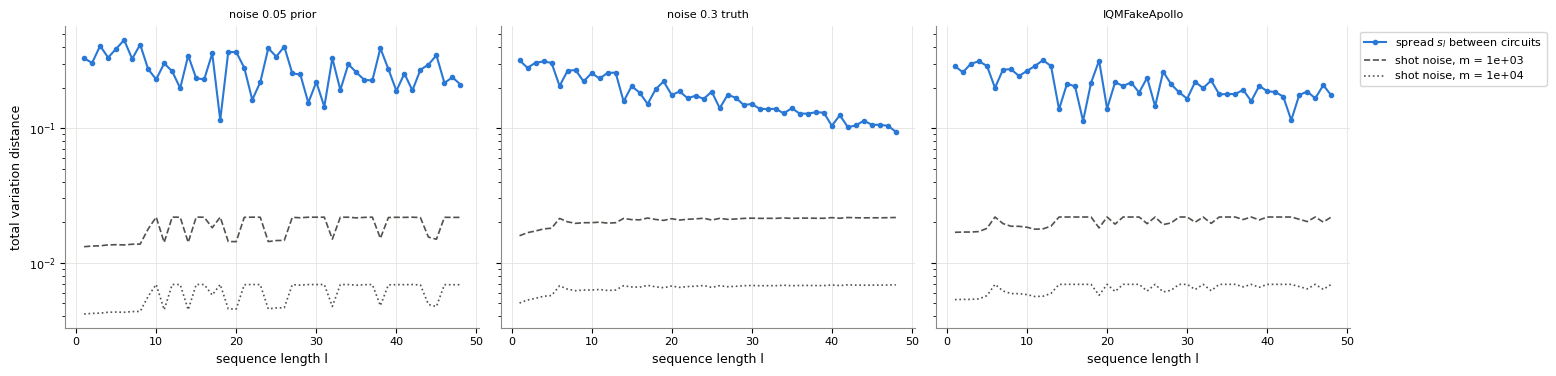

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(5.2 * len(results), 3.8), sharey=True)
for ax, (name, res) in zip(axes, results.items()):
    row = [r for r in res["rows"] if r["L"] == max(L_list)][0]
    nonempty = row["lengths"] > 0                      # random_seq_design also returns one empty sequence
    ls, s = pdz.output_spread(row["p"][nonempty], row["lengths"][nonempty])
    ax.plot(ls, s, "o-", color=COLOR["LAN"], ms=3, lw=1.5, label=r"spread $s_l$ between circuits")
    for m, style in [(1e3, "--"), (1e4, ":")]:
        noise = np.array([np.median(pdz.tvd_noise(row["p"][nonempty][row["lengths"][nonempty] == l], m)) for l in ls])
        ax.plot(ls, noise, style, color="#52514e", lw=1.2, label=f"shot noise, m = {m:.0e}")
    ax.set(yscale="log", xlabel="sequence length l", title=name)
axes[0].set_ylabel("total variation distance")
axes[-1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## Near-gauge directions

- For the 40 weakest Fisher directions of each design, the residual after removing the best-fitting GL gauge direction (`ptm_design.gl_gauge_residuals`).
- A residual below 1% means the direction changes no probability to first order, except through the small part that is not a frame change.
- Strong directions give residuals near 1.

In [6]:
rows = []
for name, res in results.items():
    for row in res["rows"]:
        rows.append({"point": name, "L_max": row["L"], "near-gauge (<1%)": row["n_near_gauge"],
                     "smallest residual": row["gl_resid"].min(), "smallest per-shot eigenvalue": row["lam1"][-1],
                     "max sigma_LAN at m = 1000": row["sigma_lan1"].max() / np.sqrt(1000),
                     "... without near-gauge": row["sigma_lan1_ng"].max() / np.sqrt(1000),
                     "Fisher time (s)": row["t_fisher"]})
display(pd.DataFrame(rows).round(4))

,point,L_max,near-gauge (<1%),smallest residual,smallest per-shot eigenvalue,max sigma_LAN at m = 1000,... without near-gauge,Fisher time (s)
0,noise 0.05 prior,14,1,0.0014,0.0000,0.0052,0.0052,43.1118
1,noise 0.05 prior,18,1,0.0013,0.0000,0.0041,0.0041,61.3169
2,noise 0.05 prior,23,1,0.0011,0.0000,0.0034,0.0034,57.5725
3,noise 0.05 prior,28,1,0.0011,0.0000,0.0031,0.0031,49.5584
4,noise 0.05 prior,32,1,0.0011,0.0000,0.0028,0.0028,57.2370
5,noise 0.05 prior,40,1,0.0010,0.0000,0.0024,0.0024,58.2243
6,noise 0.05 prior,48,1,0.0010,0.0000,0.0022,0.0022,58.6139
7,noise 0.3 truth,14,0,0.0265,0.0003,0.0068,0.0068,49.4009
8,noise 0.3 truth,18,0,0.0247,0.0004,0.0059,0.0059,50.3510
9,noise 0.3 truth,23,0,0.0244,0.0004,0.0053,0.0053,49.5104


## Reading and decision rule for the next step

**Decision rule** (from the plan; the cut is a judgment call): keep depths up to the first $L_{\max}$ where the local exponent of $m_{\rm design}$ rises above $-0.3$, plus one depth beyond. Use the depths kept for the design scans of Part C.

**Caveats.**
- **One design seed per point.** At $N=1000$ the seed spread of the worst-element width was at most 1.06 (old notebook), which is small against the gains per depth step that matter here.
- **The Fisher information sees only noise inside the rank-4 model.** Leakage and drift that grow with depth are not in these curves, so the real optimum depth can only be lower.
- **The fake-backend point has a systematic floor.** The rank-4 truncation error (table above) cannot be reduced by depth or shots.

**Conclusions:** see the next cell (written after running).

**Conclusions** (run of 2026-11-17; one design seed per point; $\delta=10^{-2}$ per element, $z=1.96$)

1. **Noise 0.05 (hardware-like, regime A): deeper keeps paying up to $L_{\max}=48$, with no turnover.**
   - $m_{\rm design}=m_{\rm vT}$ falls from 281 ($L_{\max}=14$) to 138 (23) and 47 (48). The LAN end falls from 1053 to 453 to 185.
   - Local exponents are $-0.9$ to $-2$ (noisy with one seed), with no sign of flattening.
   - The rate requirement ($10^5$ to $5\times10^5$) is irrelevant here: the bias cap ($1.9\times10^{-3}$) is far below $\delta$, so the rates need not be resolved.
   - The heuristic optimum $L\approx1/(2r)$ is in the hundreds at this noise level (PTM_PRECISION 4.3). The limit will come from noise outside the model.
2. **Noise 0.3 (regime B): the gain stops at about $L_{\max}=23$.**
   - $m_{\rm design}$ (set by the LAN width) falls from 1758 (14) to 1094 (23), then stays between 986 and 1066 up to 48. The local exponents are $-0.13$ to $+0.19$.
   - This matches the heuristic $L\approx1/(2r)\approx20$–$25$ for $1-\mu_1\approx2\times10^{-2}$.
   - The signal has **not** collapsed: the spread between circuits falls from about 0.25 to 0.09 at $l=48$, still 4× above shot noise at $m=10^3$. Long circuits remain distinguishable but no longer add information about the gates.
3. **IQMFakeApollo (realistic noise, regime B): two problems that depth does not solve.**
   - **Near-gauge directions.** 9 of the 40 weakest Fisher directions are, to within 0.1%, GL gauge directions: relaxation and dephasing can be moved between the one-qubit gates without changing any probability. With them, the worst PTM element needs $m\sim10^8$ at every depth. These quantities are not determined by any experiment; they have to be gauge-fixed over the full gauge group, or excluded from the target.
   - **Without the near-gauge directions** the requirement is set by the one-qubit rate resolution. It falls from 58 000 (14) to 16 600 (23) and 7400 (48), crossing the $m=10^4$ cap near $L_{\max}\approx36$. The LAN width alone would need 3056 (23) and 1405 (48), and vT 534 and 146.
   - Depth helps all the way to 48, and the spread between circuits stays at about 0.17–0.2 (no collapse).
   - **Truncation floor.** The rank-4 model cannot represent the CZ channel: the truncation alone moves CZ PTM elements by $1.5\times10^{-2}>\delta$. For this noise a target of $10^{-2}$ on CZ elements needs a higher Kraus rank, at least for CZ.
4. **Decision for Part C** (keep depths up to the first local exponent above $-0.3$, plus one):
   - noise 0.3: $L_{\max}\in\{14,18,23,28\}$;
   - noise 0.05 and the fake backend: all depths up to 48 are useful, and 48 is the edge of this check. A short follow-up at 64 and 96 would show where the turnover is for them, at about 1–2 min per design.
5. **Cost.**
   - The Fisher information takes 43–61 s per design at $N=600$–$1000$ and grows only slowly with $L_{\max}$.
   - The near-gauge test added about 80–100 s per design. It is only needed at the fake-backend point.
